# 01 — Découverte des données Telco

Explorer le dataset principal et la campagne pilote : premières lignes, profil des
colonnes et tableau de bord de qualité. Les diagnostics ne modifient pas les données.

**Prérequis :** sélectionner le kernel **Python (Telco Churn)**.
Les chemins sont définis dans les YAML ; `APP_ENV` sélectionne l'environnement (`dev` par défaut).


## 1. Configuration et chargement

Le package centralise la configuration, le logging et la lecture des CSV.
Les types sont inférés par pandas ; les dates ne sont pas converties explicitement.


In [1]:

# 1. Imports
import pandas as pd
from IPython.display import display

from telco_churn.data.loaders import TelcoDataLoader
from telco_churn.data.quality import DataQualityReport
from telco_churn.logging import configure_logging
from telco_churn.settings import Settings

# 2. Configuration de l'environnement
settings = Settings.load()
configure_logging(settings)

# 3. Chargement des datasets
loader = TelcoDataLoader(settings)
df = loader.load_raw("churn")
pilot_df = loader.load_raw("pilot")

# 4. Initialisation des rapports de qualité
quality_report = DataQualityReport(target_column=settings.churn_target_column)
pilot_quality_report = DataQualityReport(target_column=settings.pilot_target_column)

# 5. Vérification de l'environnement
print(f"Environnement : {settings.environment}")

2026-11-11 11:25:50 | INFO     | data.loaders | Dataset=churn path=/Users/surelmanda/2-LLops-Databricks-Projects/Telco-Churn-Optimization/data/raw/churn_clients.csv rows=38689 columns=16
2026-11-11 11:25:50 | INFO     | data.loaders | Dataset=pilot path=/Users/surelmanda/2-LLops-Databricks-Projects/Telco-Churn-Optimization/data/raw/pilote_campagne_2023.csv rows=4000 columns=10


Environnement : dev


## 2. Premières observations

Afficher les dimensions et les premières lignes de chaque source.


In [2]:

print(f"\n{'═' * 75}")
print(f" CHURN DATASET | {df.shape[0]:,} lignes × {df.shape[1]} colonnes | — cible : {settings.churn_target_column}")
print(f"{'═' * 75}")
display(df.head())

print(f"\n{'═' * 75}")
print(f" CAMPAGNE PILOTE | {pilot_df.shape[0]:,} lignes × {pilot_df.shape[1]} colonnes | — cible : {settings.pilot_target_column}")
print(f"{'═' * 75}")
display(pilot_df.head())



═══════════════════════════════════════════════════════════════════════════
 CHURN DATASET | 38,689 lignes × 16 colonnes | — cible : churn
═══════════════════════════════════════════════════════════════════════════


,customer_id,snapshot_date,signup_date,age,contract,region,dept,channel,monthly_fee,data_gb,support_calls_3m,late_payments,nps,last_invoice_amount,retention_offer_declined,churn
0,102683,2024-10-31,2020-12-04,38.0,biannuel,OCC,2,partenaire,65.15,7.9,1,1,7.0,65.15,0,0
1,100127,2024-04-30,2020-05-25,40.0,mensuel,ARA,1,telephone,48.21,14.2,0,0,NaN,48.21,0,0
2,102042,2024-04-30,2024-01-06,21.0,mensuel,IDF,9,partenaire,49.09,5.8,1,0,10.0,49.09,0,0
3,101775,2024-02-29,2021-01-01,42.0,mensuel,OCC,7,web,60.29,26.4,3,0,NaN,60.29,0,0
4,103774,2024-06-30,2020-09-17,NaN,annuel,NAQ,42,telephone,52.09,1.8,1,0,NaN,52.09,1,0



═══════════════════════════════════════════════════════════════════════════
 CAMPAGNE PILOTE | 4,000 lignes × 10 colonnes | — cible : churn_30d
═══════════════════════════════════════════════════════════════════════════


,customer_id,age,contract,region,tenure_months,monthly_fee,support_calls_3m,late_payments,contacted,churn_30d
0,503815,45.0,mensuel,PACA,53,81.88,3,1,1,0
1,503993,53.0,annuel,IDF,57,46.29,0,1,1,0
2,501016,32.0,annuel,IDF,69,81.41,1,0,1,0
3,503707,40.0,mensuel,BRE,72,50.77,1,1,1,0
4,500949,38.0,mensuel,PACA,26,80.47,1,0,1,0


## 3. Profil des colonnes et statistiques descriptives

Un tableau par source regroupe les types, valeurs manquantes, cardinalité,
statistiques numériques et exemples. Les valeurs atypiques sont signalées par
la règle de 1,5 IQR, sans être considérées automatiquement comme des erreurs.

Le taux de valeurs atypiques porte sur les valeurs numériques finies ;
le taux de valeurs uniques porte sur les valeurs non manquantes.


In [3]:
print("DATASET PRINCIPAL")
column_profile = quality_report.profile_dataset(df)
display(column_profile)

print("CAMPAGNE PILOTE")
pilot_column_profile = pilot_quality_report.profile_dataset(pilot_df)
display(pilot_column_profile)

2026-11-11 11:25:50 | INFO     | data.profiling | Computing dataset quality summary rows=38689 columns=16


DATASET PRINCIPAL


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples
0,nps,float64,12444,26245,67.84,11,0.09,9,0.07,-0.0,6.8029,7.0,10.0,1.9795,"[7.0, 10.0, 8.0, 9.0, 6.0]"
1,age,float64,36561,2128,5.50,72,0.20,469,1.28,-1.0,46.0,43.0,999.0,57.1067,"[38.0, 40.0, 21.0, 42.0, 58.0]"
2,monthly_fee,float64,36792,1897,4.90,8273,22.49,261,0.71,-109.28,60.5971,60.8,130.39,19.3073,"[65.15, 48.21, 49.09, 60.29, 52.09]"
3,customer_id,int64,38689,0,0.00,4000,10.34,0,0.0,100000.0,101999.2045,101998.0,103999.0,1152.2003,"[102683, 100127, 102042, 101775, 103774]"
4,snapshot_date,object,38689,0,0.00,12,0.03,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[2024-10-31, 2024-04-30, 2024-02-29, 2024-06-3..."
5,signup_date,object,38689,0,0.00,1787,4.62,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[2020-12-04, 2020-05-25, 2024-01-06, 2021-01-0..."
6,contract,object,38689,0,0.00,12,0.03,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[biannuel, mensuel, annuel, MENSUEL, Annuel, m..."
7,region,object,38689,0,0.00,7,0.02,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[OCC, ARA, IDF, NAQ, PACA, BRE, GES]"
8,dept,int64,38689,0,0.00,60,0.16,0,0.0,1.0,16.4566,10.0,60.0,16.4959,"[2, 1, 9, 7, 42]"
9,channel,object,38689,0,0.00,16,0.04,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[partenaire, telephone, web, boutique, BOUTIQU..."


2026-11-11 11:25:50 | INFO     | data.profiling | Computing dataset quality summary rows=4000 columns=10


CAMPAGNE PILOTE


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples
0,customer_id,int64,4000,0,0.0,4000,100.00,0,0.0,500000.0,501999.5,501999.5,503999.0,1154.8449,"[503815, 503993, 501016, 503707, 500949]"
1,age,float64,4000,0,0.0,68,1.70,20,0.5,18.0,42.2615,42.0,90.0,13.4896,"[45.0, 53.0, 32.0, 40.0, 38.0]"
2,contract,object,4000,0,0.0,3,0.07,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[mensuel, annuel, biannuel]"
3,region,object,4000,0,0.0,7,0.18,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[PACA, IDF, BRE, NAQ, ARA, OCC, GES]"
4,tenure_months,int64,4000,0,0.0,79,1.98,0,0.0,1.0,40.059,40.0,79.0,22.6033,"[53, 57, 69, 72, 26]"
5,monthly_fee,float64,4000,0,0.0,2956,73.90,13,0.33,15.0,59.8028,59.61,119.77,17.5649,"[81.88, 46.29, 81.41, 50.77, 80.47]"
6,support_calls_3m,int64,4000,0,0.0,10,0.25,21,0.53,0.0,1.2052,1.0,9.0,1.2027,"[3, 0, 1, 2, 5]"
7,late_payments,int64,4000,0,0.0,5,0.12,38,0.95,0.0,0.4183,0.0,4.0,0.653,"[1, 0, 2, 3, 4]"
8,contacted,int64,4000,0,0.0,2,0.05,0,0.0,0.0,0.532,1.0,1.0,0.499,"[1, 0]"
9,churn_30d,int64,4000,0,0.0,2,0.05,178,4.45,0.0,0.0445,0.0,1.0,0.2062,"[0, 1]"


## 4. Tableau de bord de qualité

Chaque tableau de bord présente les dimensions, les lignes entièrement dupliquées,
les valeurs manquantes, la distribution de la cible et les types de colonnes.
Les doublons de lignes sont distincts des identifiants clients répétés.

`churn` et `churn_30d` restent séparés : leurs définitions et horizons sont à confirmer.
Les classes affichées excluent les cibles manquantes.


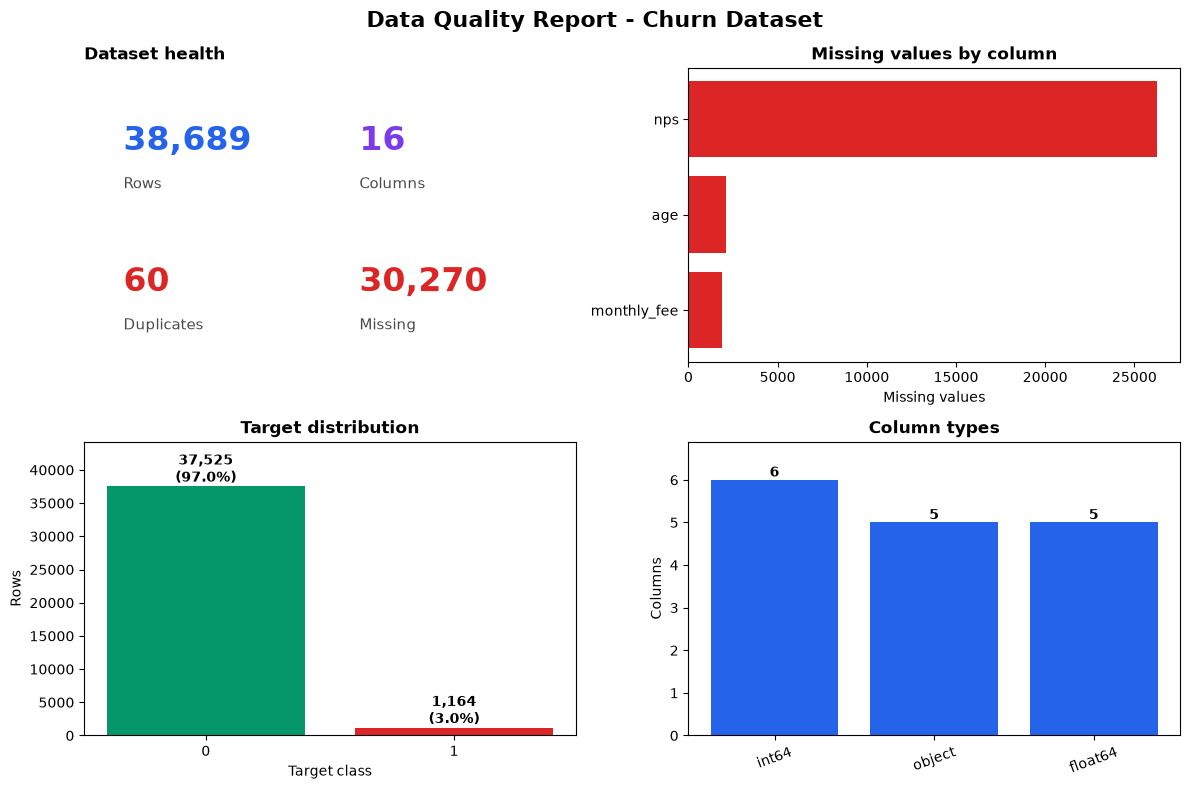

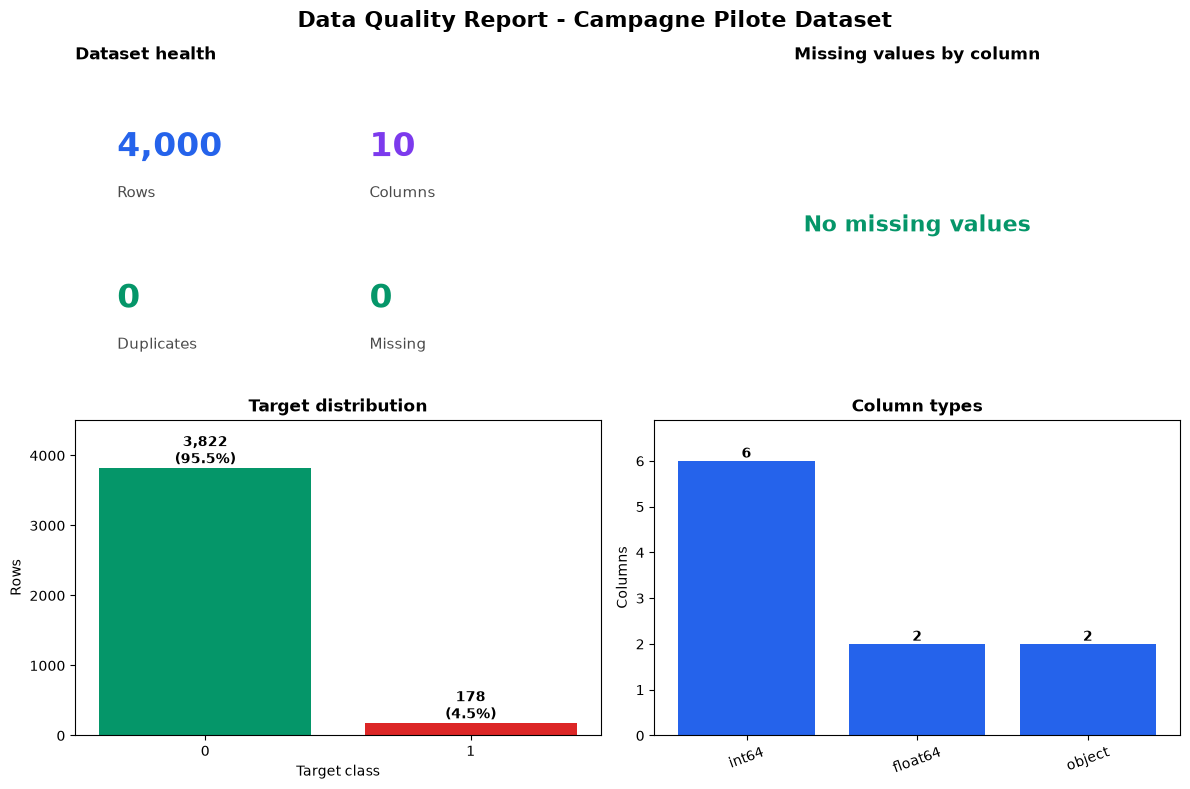

In [4]:
quality_report.show(df, title="Data Quality Report - Churn Dataset")
pilot_quality_report.show(pilot_df, title="Data Quality Report - Campagne Pilote Dataset")

## 5. Comparaison des structures

La vue côte à côte permet d'identifier les colonnes communes et spécifiques.
Un nom identique ne garantit pas une définition métier identique.


In [5]:
schema_comparison = pd.concat(
    [
        df.dtypes.astype(str).rename("principal"),
        pilot_df.dtypes.astype(str).rename("pilote"),
    ],
    axis=1,
).fillna("absente")
display(schema_comparison)

,principal,pilote
customer_id,int64,int64
snapshot_date,object,absente
signup_date,object,absente
age,float64,float64
contract,object,object
region,object,object
dept,int64,absente
channel,object,absente
monthly_fee,float64,float64
data_gb,float64,absente


## 6. Points à confirmer

- Le principal contient-il plusieurs observations par client, repérées par `snapshot_date` ?
- Quelles colonnes nécessitent une investigation des valeurs manquantes ou des types ?
- Comment sont définis `churn` et `churn_30d`, et sur quels horizons ?
- Que signifie `contacted`, et comment la population du pilote a-t-elle été constituée ?

Ces diagnostics détectent les valeurs manquantes reconnues par pandas, pas tous les
codes métier invalides. Les investigations détaillées seront traitées dans le notebook 02.
